# 演習1：次の行列$K$の固有値や固有値の差を推定（！）しよう

$$K=\begin{pmatrix}1/4&0\\0&3/4\end{pmatrix}
=\begin{pmatrix}0.010_2&0\\0&0.110_2\end{pmatrix},\qquad U=e^{2\pi iK}.$$

固有状態を$|0\rangle,|1\rangle$、対応する固有値を$\phi_0=1/4,\phi_1=3/4$とします。
$$U|j\rangle=e^{2\pi i\phi_j}|j\rangle,\quad
U^L|j\rangle=e^{2\pi iL\phi_j}|j\rangle,\quad \Delta=\phi_1-\phi_0=1/2.$$

答えがわかっている小さな行列で、回路の測定結果から答えを取り出す手順を体験します。
QPEではビット列を読みます。BPE・BPDEでは、**候補値を走査→山をGaussianフィット→事前と掛けて更新→次の測定**と進みます。
BPEは固有値、BPDEは固有値の差を求めます。演習05と同じ更新の流れを使い、結果を一組の図と表にまとめます。

ここで固有値は「1周を1とする位相」にもなります。$1/4$は$\pi/2$ラジアンです。
$U$では整数だけ違う固有値を区別できないので、今回は$[0,1)$の範囲で考えます。
測定はすべてシミュレーションです。元の01は変更しない比較用の改訂案です。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"

### 実行準備

次のセルはライブラリと描画関数を定義します。`draw`は回路図、`show_probs`は
厳密確率と指定shotsの模擬測定を描きます。推定する物理量はまだ設定しません。

In [2]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
TAU = 2 * np.pi
ATOL = 1e-10

def draw(qc, fold=110):
    # 回路を画像で表示。数値計算にはこの描画関数は使わない。
    fig = qc.draw(output="mpl", fold=fold)
    display(fig)
    plt.close(fig)

def draw_measured(qc, qubits):
    # 描画用のコピーだけに測定を追加。厳密確率は測定前の回路から計算する。
    measured = qc.copy()
    readout = ClassicalRegister(len(qubits), "readout")
    measured.add_register(readout)
    measured.measure(qubits, readout)
    draw(measured)

def show_probs(probabilities, title, ax=None, shots=None, seed=123):
    p = np.asarray(probabilities, dtype=float)
    m = int(np.log2(len(p)))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3))
    x = np.arange(len(p))
    ax.bar(x, p, width=0.65, label="Exact probability", alpha=0.75)
    if shots:
        counts = np.random.default_rng(seed).multinomial(shots, p / p.sum())
        ax.plot(x, counts / shots, "ko", ms=4, label=f"{shots} simulated shots")
    ax.set_xticks(x, [format(i, f"0{m}b") for i in x], rotation=60 if m > 3 else 0)
    ax.set(xlabel="Measured bits (MSB ... LSB)", ylabel="Probability", title=title)
    ax.legend(fontsize=8)
    return ax

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__, "Qiskit:", qiskit.__version__)
print("以降のshot/countはすべてシミュレーションです。")

Python: 3.12.7
NumPy: 2.4.6 Matplotlib: 3.10.0 Qiskit: 2.4.1
以降のshot/countはすべてシミュレーションです。


## 0．行列と入力状態を用意する

Qiskitのケットは$|q_{n-1}\cdots q_0\rangle$順です。
QPEの補助は$q_0\ldots q_{m-1}$、系は$q_m$とします。
以降の2 qubit回路は$q_0=a$（補助）、$q_1=s$（系）で、配列のケットは$|s,a\rangle$です。
説明で$|a,s\rangle$と書くときとは表示順が逆です。

次セルで`K`、`PHASES`、`GAP`と入力状態を定義します。
`psi_mixed`は二つの固有状態の**純粋な重ね合わせ**で、密度行列の混合状態ではありません。

In [3]:
PHASES = np.array([1/4, 3/4])
K = np.diag(PHASES)
GAP = PHASES[1]-PHASES[0]
zero = np.array([1,0], complex)
one = np.array([0,1], complex)
psi_mixed = np.sqrt(.75)*zero + np.sqrt(.25)*one

def u_power(L, phases=PHASES):
    return np.diag(np.exp(1j*TAU*L*np.asarray(phases)))

print('K =',K,'\nU =',u_power(1))
for phase in PHASES:
    print(f'phase={phase}: 0.{int(8*phase):03b}_2')
assert GAP == .5
np.testing.assert_allclose(u_power(1).conj().T@u_power(1),np.eye(2),atol=ATOL)

K = [[0.25 0.  ]
 [0.   0.75]] 
U = [[ 0.+1.j  0.+0.j]
 [ 0.+0.j -0.-1.j]]
phase=0.25: 0.010_2
phase=0.75: 0.110_2


## 1．共通部品：位相を0/1の確率へ変える

位相因子だけでは状態の測定確率は変わりません。補助の二つの枝を干渉させます。
下の●は制御、P(β)=diag(1,exp(iβ))、MはZ基底の測定です。時間は左から右です。

```text
a: |0> ──H────●────P(β)──H──M
              │
s: |ψ> ─────[U^L]────────────
```

系が固有状態$|\phi\rangle$なら、制御Uの後は
$$(|0\rangle+e^{2\pi iL\phi}|1\rangle)|\phi\rangle/\sqrt2.$$
最後のHで二つの振幅が足し引きされ、
$$P(a=0\mid\phi,L,\beta)=\frac{1+\cos(2\pi L\phi+\beta)}2.$$
候補$\epsilon$に対し$\beta=-2\pi L\epsilon$とすると、ピークは
$\epsilon=\phi+k/L$です。長時間は感度を上げると同時に候補も増やします。

**予想：** $\phi=1/4$、$L=1,2,4$では、区間$[0,1)$に何個のピークがあるか。

<details><summary>解答例</summary>
順に1、2、4個です。ピーク条件はε=1/4+k/Lで、周期1の区間にL個あります。
</details>

次セルは回路の状態ベクトルと上の余弦式を照合し、候補を掃引します。

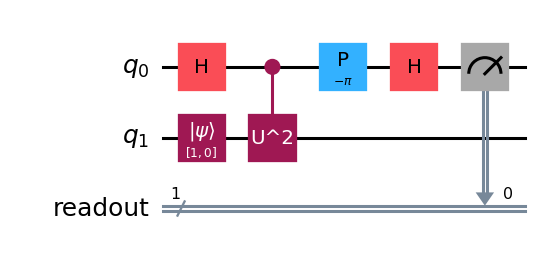

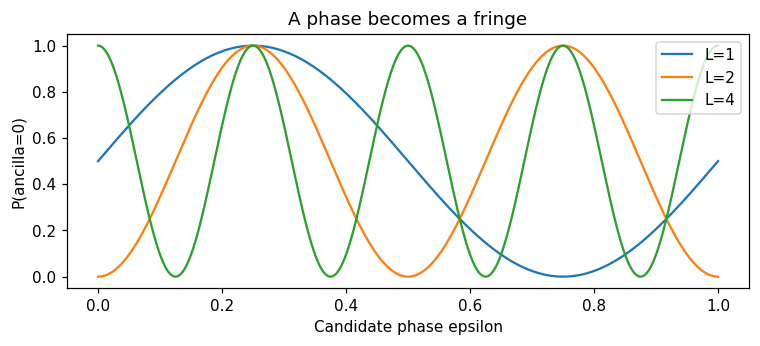

In [4]:
def ramsey_circuit(psi, L=1, beta=0.0):
    qc = QuantumCircuit(2)
    qc.initialize(psi, 1)
    qc.h(0)
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}").control(), [0, 1])
    qc.p(beta, 0)
    qc.h(0)
    return qc

def ancilla_zero(qc):
    return float(Statevector.from_instruction(qc).probabilities([0])[0])

def bpe_probability(weights, L, beta):
    # betaはスカラーでも配列でもよい。
    amplitude = np.dot(weights, np.exp(1j * TAU * L * PHASES))
    return 0.5 * (1 + np.real(np.exp(1j * beta) * amplitude))

draw_measured(ramsey_circuit(zero, L=2, beta=-TAU * 2 * PHASES[0]), [0])
eps = np.linspace(0, 1, 801)
fig, ax = plt.subplots(figsize=(8, 3))
for L in [1, 2, 4]:
    ax.plot(eps, bpe_probability([1, 0], L, -TAU*L*eps), label=f"L={L}")
    for e in [0.03, 0.125, 0.36]:
        actual = ancilla_zero(ramsey_circuit(zero, L, -TAU*L*e))
        assert np.isclose(actual, bpe_probability([1, 0], L, -TAU*L*e), atol=ATOL)
ax.set(xlabel="Candidate phase epsilon", ylabel="P(ancilla=0)", title="A phase becomes a fringe")
ax.legend(); plt.show()

### 課題1：干渉と周期

1. 最後のHを外して補助を測ると、位相は読めるか。
2. $L=8$を図に追加し、候補が$1/L$ずつ繰り返すことを確認する。

<details><summary>解答例</summary>
最後のHの前は補助0/1の絶対値が等しく、Z測定はどちらも1/2です。
候補を1/L動かすと余弦の引数が2π変わるため、ピークがL個あります（端点1は0と同一）。
</details>

## 2．IQFT型QPE：位相をビット列へ写す

一度のQPE回路で補助$m$個を使い、$L=1,2,4,\ldots,2^{m-1}$の情報を量子的にまとめます。
$m=3$の模式図です。右の3線をまとめた箱が逆QFTです。

```text
q0: |0> ──H──●──────────────┌────────┐──M
             │              │        │
q1: |0> ──H──┼───●──────────│ IQFT   │──M
             │   │          │        │
q2: |0> ──H──┼───┼───●──────└────────┘──M
             │   │   │
s : |φ> ────[U]─[U²]─[U⁴]────────────────
```

固有状態なら、逆QFT前の補助は
$$2^{-m/2}\sum_{x=0}^{2^m-1}e^{2\pi ix\phi}|x\rangle.$$
逆QFTは$|x\rangle\mapsto 2^{-m/2}\sum_y e^{-2\pi ixy/2^m}|y\rangle$なので、
$$P(y\mid\phi)=\left|2^{-m}\sum_x e^{2\pi ix(\phi-y/2^m)}\right|^2.$$
$\phi=y_0/2^m$なら同位相で足し合うのは$y=y_0$だけです。
本例では010と110が確率1で出ます。制御Uのどの補助も、逆QFT前に単独で「第r桁」を読んでいるわけではありません。

次セルの`inverse_qft`はH・制御位相・SWAPを実装し、定義行列と照合します。
`QPE_BITS`を変更して、固有状態の出力を比較してください。

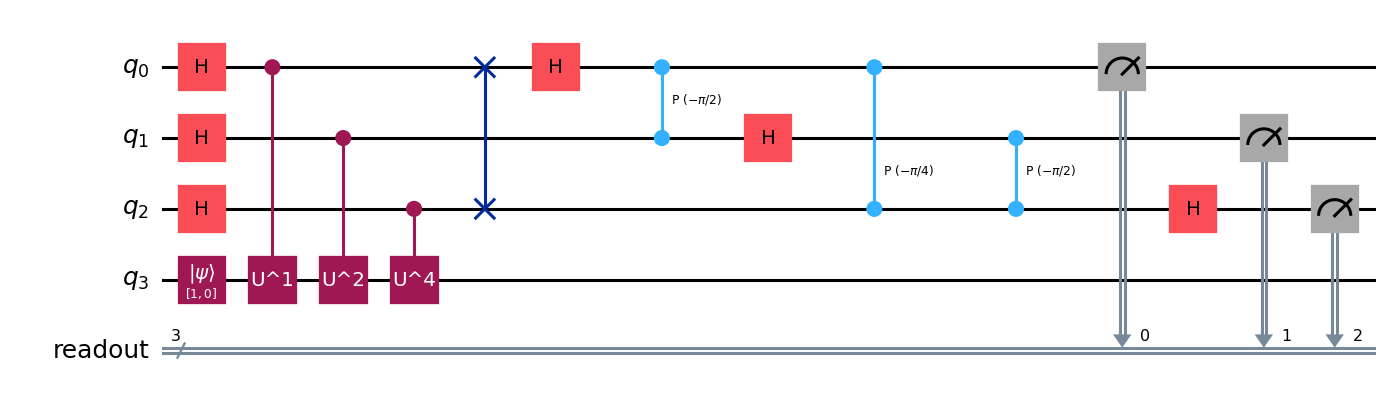

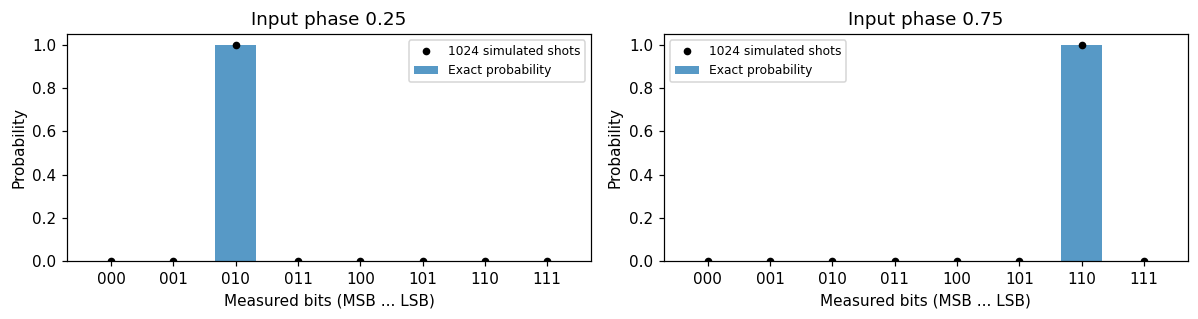

In [5]:
def inverse_qft(m):
    qc = QuantumCircuit(m, name="QFT_dg")
    for j in range(m // 2):
        qc.swap(j, m - 1 - j)
    for j in range(m):
        for ell in range(j):
            qc.cp(-np.pi / 2**(j - ell), j, ell)
        qc.h(j)
    return qc

def qpe_circuit(psi, m=3, phases=PHASES):
    qc = QuantumCircuit(m + 1)
    qc.initialize(psi, m)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(u_power(2**r, phases), label=f"U^{2**r}").control(), [r, m])
    qc.compose(inverse_qft(m), list(range(m)), inplace=True)
    return qc

def qpe_distribution(psi, m=3, phases=PHASES):
    state = Statevector.from_instruction(qpe_circuit(psi, m, phases))
    return state.probabilities(list(range(m)))

QPE_BITS = 3  # 2, 3, 4を比較
M = 2**QPE_BITS
x = np.arange(M)
np.testing.assert_allclose(Operator(inverse_qft(QPE_BITS)).data,
    np.exp(-1j*TAU*np.outer(x,x)/M)/np.sqrt(M),atol=ATOL)
draw_measured(qpe_circuit(zero,QPE_BITS),list(range(QPE_BITS)))
fig,axes=plt.subplots(1,2,figsize=(11,3))
for ax,psi,phase in zip(axes,[zero,one],PHASES):
    p=qpe_distribution(psi,QPE_BITS)
    show_probs(p,f'Input phase {phase}',ax,shots=1024)
    assert np.isclose(p[int(M*phase)],1,atol=ATOL)
plt.tight_layout();plt.show();plt.close(fig)


### 2.1．固有状態の重ね合わせを入力する

$$|\psi\rangle=\sqrt{3/4}|0\rangle+\sqrt{1/4}|1\rangle.$$
$m=3$なら、逆QFT後の状態は（ここだけ補助レジスタを先に書いて）
$$\sqrt{3/4}|010\rangle_a|0\rangle_s+\sqrt{1/4}|110\rangle_a|1\rangle_s.$$
位相の平均ではなく、固有成分ごとの位相が重なりの確率で出ます。
次セルはヒストグラムと、補助の結果に条件付けた系の状態を表示します。

ancilla=010, probability=0.750, system P(0),P(1)=[1. 0.]
ancilla=110, probability=0.250, system P(0),P(1)=[0. 1.]


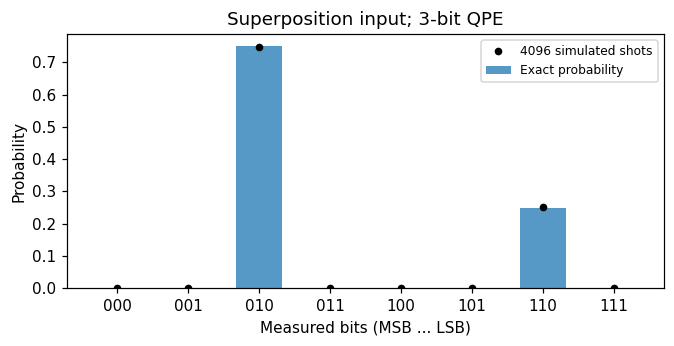

In [6]:
GROUND_WEIGHT = .75  # .25へ変更して再実行
psi_mixed=np.sqrt(GROUND_WEIGHT)*zero+np.sqrt(1-GROUND_WEIGHT)*one
p_qpe=qpe_distribution(psi_mixed,m=3)
show_probs(p_qpe,'Superposition input; 3-bit QPE',shots=4096);plt.show();plt.close('all')
expected=np.zeros(8);expected[2]=GROUND_WEIGHT;expected[6]=1-GROUND_WEIGHT
np.testing.assert_allclose(p_qpe,expected,atol=ATOL)
joint=Statevector.from_instruction(qpe_circuit(psi_mixed,m=3)).data.reshape(2,8)
for y in [2,6]:
    if p_qpe[y]>ATOL:
        conditional=joint[:,y]/np.sqrt(p_qpe[y])
        print(f'ancilla={y:03b}, probability={p_qpe[y]:.3f}, system P(0),P(1)={abs(conditional)**2}')

### 課題2：QPEの出力を読む

1. `QPE_BITS`を2、3、4へ変える。出力整数と位相y/2^mを区別して記録する。
2. `GROUND_WEIGHT`を.75から.25へ変える。変わるのはピークの場所か、頻度か。

<details><summary>解答例</summary>
位相1/4、3/4は2ビットで表せます。3ビットでは010/110、2ビットでは01/11です。
重みを変えても位相は変わらず、010と110の確率が1/4と3/4になります。
</details>

## 3．BPE：候補を動かすと、固有値の位置に山が出る

第1節の回路に固有状態$|0\rangle$を入れます。未知として探す量はその固有値$\phi$です。
候補値を$\epsilon$とし、候補を一つ選ぶたびに、回路の補正角を
$$\boxed{\beta=-2\pi L\epsilon}$$
に設定します。今回は$\beta=0,-\pi/2$を交互に選ぶ方式は使いません。
候補を掃引すると、測定確率は
$$P_0(\epsilon)=\frac{1+\cos[2\pi L(\phi-\epsilon)]}{2}$$
となり、$\epsilon=\phi$に山が出ます。第1節の横軸をそのまま使います。
各ショットでは系と補助を準備し直します。

```text
事前の中心μ・幅σ → Lと候補εの列を決める
    → 各εで β=−2πLε を回路に設定 → 補助0の確率／頻度を測る
    → 山をGaussianフィット → 事前と掛けて事後へ → 次の事前
```

### 3.1．一つの山を追う条件を決める

周期的な山を一つのGaussianで表すには、どの山を追うかを先に絞る必要があります。
この例では粗い事前$\mu=0.30,\ \sigma=0.08$から始めます。
これは答えを知らずに全域探索する例ではなく、**粗い推定を改善する例**です。
真値は図と検算にだけ使い、測定計画・フィット・更新には渡しません。

簡単な測定計画として、$L=\max(1,\lfloor0.20/\sigma\rfloor)$、
半幅$h=\min(2\sigma,1/(4L))$とし、候補を$[\mu-h,\mu+h]$に21点置きます。
$L$を増やすと山は細くなりますが、間隔$1/L$で別の山も出ます。
この計画では探索幅を周期より狭く保ちます。ただし真の山が窓内にある保証はなく、外れたら事前を見直します。
05と同じ「事前から計画する」構造ですが、この無次元の例の$L$選択係数は説明用です。

### 3.2．測定曲線をGaussianで近似し、分布を更新する

測った山を
$$g(\epsilon)=A\exp[-(\epsilon-m)^2/(2w)]$$
で近似します。$m$が山の中心、$w$が幅の二乗です。
事前を$N(\mu,v)$（$v=\sigma^2$）とすると、演習05と同じGaussianの積で
$$v'=\left(\frac1v+\frac1w\right)^{-1},\qquad
\mu'=v'\left(\frac\mu v+\frac m w\right)$$
と更新します。振幅$A$は分布の正規化で消えます。

**元の曲線は余弦で、Gaussianではありません。これは信号の山を使う近似更新です。**
$w$はフィット曲線の幅であり、フィット中心の統計的な分散ではありません。
事後の幅を、shotsに基づく厳密な信頼区間・信用区間とは解釈しません。
残差は更新履歴の表で確認します。

In [7]:
from scipy.optimize import curve_fit

def single_phase_model(phi, L, beta):
    return .5*(1+np.cos(TAU*L*phi+beta))

def gaussian(x, amplitude, mean, sd):
    return amplitude*np.exp(-.5*((np.asarray(x)-mean)/sd)**2)

def choose_scan(mu, variance, points=21):
    if not np.isfinite(mu) or not np.isfinite(variance) or variance <= 0:
        raise ValueError('有限の中心と正の分散が必要です')
    sd=np.sqrt(variance)
    L=max(1, int(np.floor(.20/sd)))
    halfwidth=min(2*sd,1/(4*L))
    eps=np.linspace(mu-halfwidth, mu+halfwidth, points)
    return L,eps

def gaussian_round(signal, mu, variance, rng, mode='exact', shots=256):
    # signalは実際の回路から確率を返す。真値を計画・更新へ渡さない。
    if mode not in ('exact','shots'):
        raise ValueError("modeは'exact'または'shots'")
    if not isinstance(shots, (int,np.integer)) or shots <= 0:
        raise ValueError('shotsは正の整数')
    L,eps=choose_scan(mu,variance)
    beta=-TAU*L*eps
    exact=np.array([signal(L,float(b)) for b in beta])
    if np.any(exact < -ATOL) or np.any(exact > 1+ATOL):
        raise ValueError('回路確率が範囲外です')
    exact=np.clip(exact,0,1)
    counts=rng.binomial(shots,exact) if mode=='shots' else None
    observed=counts/shots if counts is not None else exact.copy()
    span=eps[-1]-eps[0]
    params,_=curve_fit(gaussian,eps,observed,
        p0=[1.,mu,np.sqrt(variance)],
        bounds=([.01,eps[0],span*.01],[2.,eps[-1],span*10]),maxfev=20000)
    amplitude,m,sd=params
    w=sd**2
    new_v=1/(1/variance+1/w)
    new_mu=new_v*(mu/variance+m/w)
    fitted=gaussian(eps,*params)
    return dict(prior_mu=mu,prior_v=variance,L=L,eps=eps,beta=beta,
        exact=exact,observed=observed,counts=counts,shots=shots,mode=mode,
        amplitude=amplitude,fit_mu=m,fit_v=w,posterior_mu=new_mu,
        posterior_v=new_v,rmse=float(np.sqrt(np.mean((observed-fitted)**2))))


def gaussian_updates(signal, initial_mu, initial_sd, rounds=5, mode='shots', shots=256, seed=20261108):
    rng=np.random.default_rng(seed)
    mu,v=initial_mu,initial_sd**2
    rows=[]
    for _ in range(rounds):
        row=gaussian_round(signal,mu,v,rng,mode,shots)
        rows.append(row)
        mu,v=row['posterior_mu'],row['posterior_v']
    return rows

def plot_updates(rows, truth, title, xlabel='Phase or phase gap / cycles'):
    if not rows:
        print('No updates');return
    mu,v=rows[0]['prior_mu'],rows[0]['prior_v']
    final=rows[-1]
    final_mu,final_sd=final['posterior_mu'],np.sqrt(final['posterior_v'])
    density=lambda x,m,v: gaussian(x,1/np.sqrt(TAU*v),m,np.sqrt(v))
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    x=np.linspace(min(mu-4*np.sqrt(v),truth-.02),max(mu+4*np.sqrt(v),truth+.02),1201)
    axes[0].plot(x,density(x,mu,v),':',label='Gaussian prior')
    for i in sorted(set([0,len(rows)//2,len(rows)-1])):
        r=rows[i]
        axes[0].plot(x,density(x,r['posterior_mu'],r['posterior_v']),label=f'After {i+1} updates')
    # Zoom around the final distribution, including the reference for checking.
    low=min(final_mu-4*final_sd,truth-final_sd)
    high=max(final_mu+4*final_sd,truth+final_sd)
    xx=np.linspace(low,high,801)
    axes[1].plot(xx,density(xx,final_mu,final_sd**2),label='Final posterior')
    for ax in axes:
        ax.axvline(truth,color='black',ls='--',label='Reference (check only)')
        ax.set(xlabel=xlabel,ylabel='Gaussian density');ax.legend(fontsize=8)
    axes[1].set_xlim(low,high)
    fig.suptitle(title);plt.tight_layout();plt.show();plt.close(fig)

def print_data(rows):
    print('update  L   fit center    post mean     post SD    fit RMSE')
    for i,r in enumerate(rows,1):
        print(f"{i:3d} {r['L']:5d} {r['fit_mu']:12.7f} {r['posterior_mu']:12.7f} "
              f"{np.sqrt(r['posterior_v']):11.6f} {r['rmse']:10.4g}")
    total_shots=sum(len(r['eps'])*r['shots'] for r in rows if r['counts'] is not None)
    total_u=sum(len(r['eps'])*r['shots']*r['L'] for r in rows if r['counts'] is not None)
    print('Simulated shots:',total_shots,'U repetitions:',total_u)
    if rows:
        r=rows[-1]
        print('Final mean:',r['posterior_mu'],'Gaussian SD:',np.sqrt(r['posterior_v']))

### 3.3．BPEの測定例と更新履歴

`MODE='shots'`は各候補を`SHOTS`回測る模擬測定、`'exact'`はshot noiseなしです。
測定・フィット・更新をまとめて実行し、**左：事前と途中・最終の分布、右：最終分布の拡大**を表示します。
表は更新ごとのL、フィット中心、事後平均・幅、残差です。各測定点のcountsやフィット係数は内部の`bpe_rows`・`b_rows`・`c_rows`に保持し、ラウンド別の図は描きません。
表示幅はGaussian近似更新の幅で、shotsから導く厳密な統計誤差ではありません。

update  L   fit center    post mean     post SD    fit RMSE
  1     2    0.2488007    0.2810733    0.063515    0.01799
  2     3    0.2514400    0.2673806    0.046584    0.02877
  3     4    0.2499813    0.2598467    0.035077    0.01352
  4     5    0.2497851    0.2558768    0.027294    0.01816
  5     7    0.2497757    0.2531542    0.020311    0.01801
Simulated shots: 26880 U repetitions: 112896
Final mean: 0.2531541870212855 Gaussian SD: 0.020310518253300967


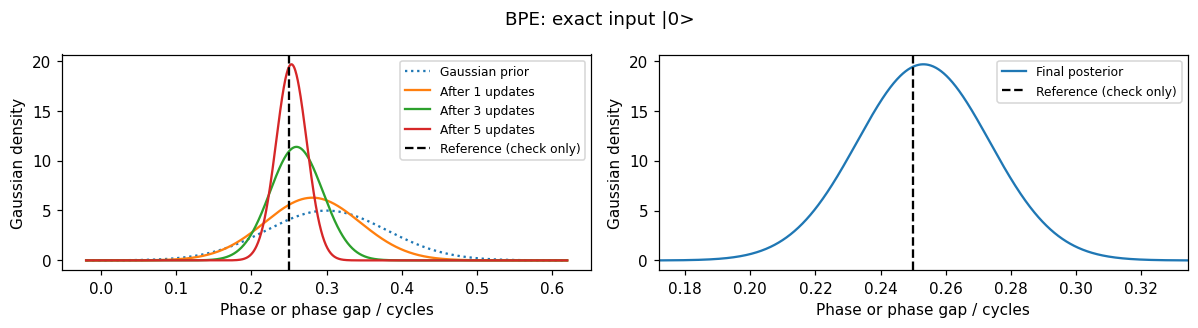

In [8]:
SHOTS = 256
SEED = 20261108
MODE = 'shots'  # 'exact'ならshot noiseなし
N_UPDATES = 5

bpe_rows = gaussian_updates(lambda L,b: ancilla_zero(ramsey_circuit(zero,L,b)),
    initial_mu=.30, initial_sd=.08, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=SEED)
plot_updates(bpe_rows, PHASES[0], 'BPE: exact input |0>')
print_data(bpe_rows)

### 確認と解答：BPEで何が更新されるか

1. 候補$\epsilon$を変えると、回路の何が変わるか。  
   **解答：** $L$を固定した走査中は補正角$\beta=-2\pi L\epsilon$が変わります。$K$や入力状態は変わりません。
2. shotsを増やすとGaussian更新の幅は必ず$1/\sqrt{\mathrm{shots}}$で狭くなるか。  
   **解答：** いいえ。頻度のばらつきは減りますが、ここで使う幅は信号の山の幅です。
   この近似更新は二項尤度から得る厳密な事後分布ではありません。
3. 初期事前を$\mu=0.80,\sigma=0.02$にすれば$1/4$へ戻るか。  
   **解答：** 保証できません。周期の別の山や窓の端へフィットし得ます。狭い事前を過信せず、粗い走査からやり直します。

## 4．BPDE・Fig. 1B型：二つの固有位相の差を読む

補助の二つの枝へ異なる固有状態を準備します。
$$|\Psi\rangle=(|0\rangle_a|0\rangle_s+|1\rangle_a|1\rangle_s)/\sqrt2.$$
準備を$W_B$とすると、回路は次の形です。箱は両線に作用します。

```text
a: |0> ──┌─────┐────────P(β)──┌──────┐──M_a
         │ W_B │              │ W_B† │
s: |0> ──└─────┘──[U^L]───────└──────┘─────
```

$U^L$は**系にだけ、補助で制御せず**作用させます。準備の制御操作は残ります。
時間発展後の二つの枝には$e^{2\pi iL\phi_0}$と$e^{i\beta}e^{2\pi iL\phi_1}$が付きます。
共通位相をくくると、相対位相は$2\pi L\Delta+\beta$です。
$$P_B(a=0)=\frac{1+\cos(2\pi L\Delta+\beta)}2,\qquad\Delta=1/2.$$

次セルは準備・逆準備を含む回路の確率を式と照合します。
`eta=0`が厳密準備です。`eta>0`は励起側に$|0\rangle$が混入した診断例で、
信号は$[1+\eta\cos\beta+(1-\eta)\cos(2\pi L\Delta+\beta)]/2$になります。

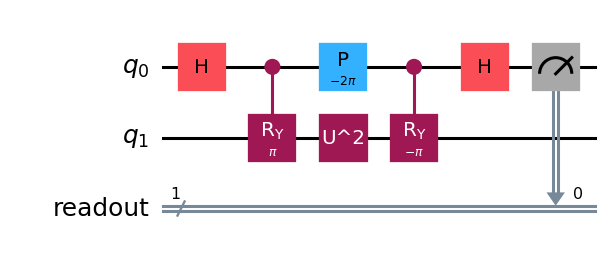

In [9]:
def preparation_b(eta=0.0):
    qc = QuantumCircuit(2, name="W_B")  # q0=a, q1=s
    qc.h(0)
    qc.cry(2*np.arccos(np.sqrt(eta)), 0, 1)
    return qc

def bpde_circuit(eta=0.0, L=1, beta=0.0):
    prep = preparation_b(eta)
    qc = QuantumCircuit(2)
    qc.compose(prep, inplace=True)
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}"), [1])
    qc.p(beta, 0)
    qc.compose(prep.inverse(), inplace=True)
    return qc

def bpde_probability(eta, L, beta):
    return 0.5*(1 + eta*np.cos(beta) + (1-eta)*np.cos(TAU*L*GAP+beta))

draw_measured(bpde_circuit(eta=0, L=2, beta=-TAU*2*GAP), [0])
for eta in [0, 0.25, 0.7]:
    for L in [1, 2, 5]:
        for beta in [0.0, 0.31, -1.7]:
            assert np.isclose(ancilla_zero(bpde_circuit(eta, L, beta)),
                              bpde_probability(eta, L, beta), atol=ATOL)

### 4.1．BPDEでも同じ走査・Gaussian更新を行う

候補をギャップ$\epsilon$に変え、やはり$\beta=-2\pi L\epsilon$とします。
$$P_B(a=0\mid\epsilon)=\frac{1+\cos[2\pi L(\Delta-\epsilon)]}{2}.$$
山の中心が固有値$\phi$から差$\Delta$へ変わるだけです。計画・フィット・更新関数は再利用します。
粗い事前は$\mu=0.55,\sigma=0.08$とし、真値$\Delta=0.5$は採点用にだけ使います。

update  L   fit center    post mean     post SD    fit RMSE
  1     2    0.5018374    0.5319112    0.063216     0.0192
  2     3    0.4996466    0.5173119    0.046776    0.02351
  3     4    0.5012009    0.5103041    0.035161    0.01843
  4     5    0.4989260    0.5056847    0.027099    0.01334
  5     7    0.4992787    0.5029222    0.020437    0.02285
Simulated shots: 26880 U repetitions: 112896
Final mean: 0.5029221859004097 Gaussian SD: 0.020437321710012807


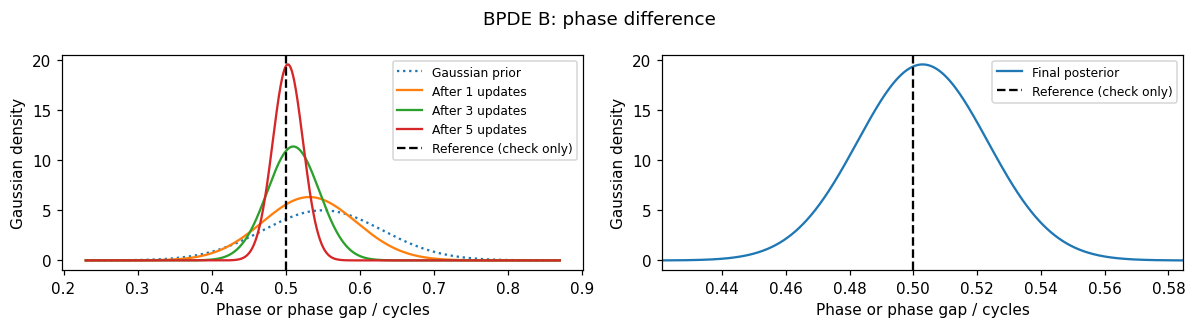

In [10]:
b_rows = gaussian_updates(lambda L,b: ancilla_zero(bpde_circuit(eta=0,L=L,beta=b)),
    initial_mu=.55, initial_sd=.08, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=83)
plot_updates(b_rows, GAP, 'BPDE B: phase difference')
print_data(b_rows)

### 課題4：絶対位相と差を区別する

$K\to K+cI$とすると、$U^L$の両固有位相に$cL$が加わります。
式から、BPEの位相とBPDEの差がどう変わるか説明してください。
また、`eta=1`では二つの枝が同じ状態になります。何の差を測っているでしょうか。

<details><summary>解答例</summary>
BPEはφ+c（周期1）を読みます。BPDEでは共通位相が消え、差は変わりません。
eta=1では差0の信号です。近似状態を使っても本節の単一ギャップ尤度が常に正しいわけではありません。
</details>

## 5．Fig. 1C型：全0へ戻った回数で差を読む

一般の準備$W$で作った状態について、逆準備後の**全0**確率は
$$P_C(00)=|\langle\Psi|(P_a(\beta)\otimes U^L)|\Psi\rangle|^2.$$
枝の状態を$|\psi_0\rangle,|\psi_1\rangle$として
$$a_j=\langle\psi_j|U^L|\psi_j\rangle,\qquad
P_C(00)=\tfrac14|a_0+e^{i\beta}a_1|^2.$$
これは演習3〜5の全0測定と同じ式です。厳密固有状態ではFig. 1B型と同じ余弦になります。

```text
a: |0> ──┌─────┐────────P(β)──┌──────┐──M_a──┐
         │ W_C │              │ W_C† │       ├─ count(a=0 AND s=0)
s: |0> ──└─────┘──[U^L]───────└──────┘──M_s──┘
```

**同じ状態を準備しても、補助だけの測定は同じとは限りません。**
説明用に$W_C=W_B\,\mathrm{SWAP}$とします。初期00はSWAPで変わらず、準備状態は同じです。
逆準備の最後のSWAPで、Fig. 1B型で補助に出ていた情報が系へ移ります。
厳密準備eta=0のこの例では補助0の確率は常に1ですが、全0確率は位相差で変わります。
SWAPは原著の回路そのものではなく、Fig. 1C型の読出し原理を示す小さな実例です。

次セルはBとCの測定確率を掃引します。L=1、β=0では相対位相πなので、
数式の順$|a,s\rangle$でBは10、Cは01となることを確認してください。

B output probabilities in |a,s> order: {'00': 0.0, '01': 0.0, '10': 1.0, '11': 0.0}
C output probabilities in |a,s> order: {'00': 0.0, '01': 1.0, '10': 0.0, '11': 0.0}


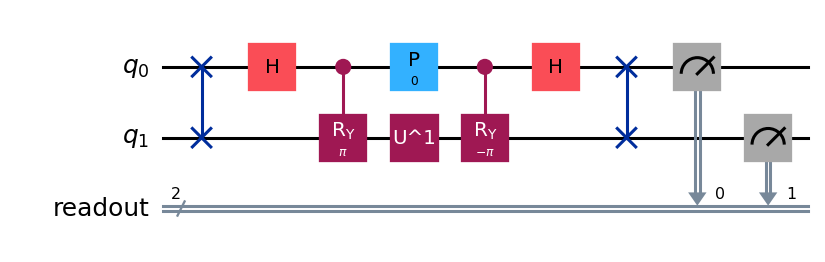

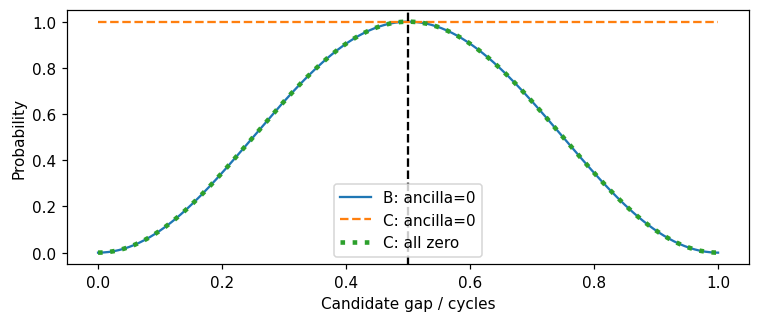

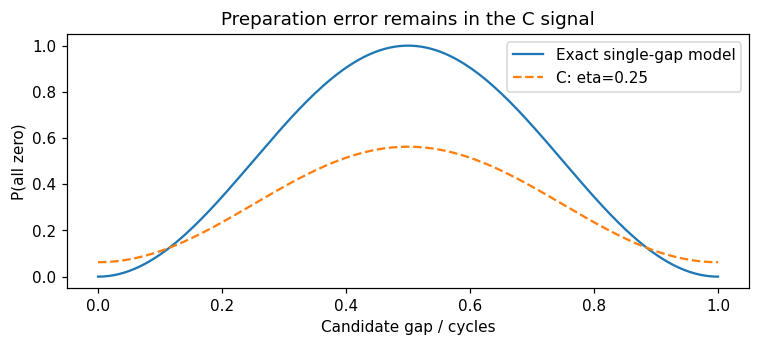

In [11]:
def preparation_c(eta=0.):
    qc=QuantumCircuit(2,name='W_C')
    qc.swap(0,1)
    qc.compose(preparation_b(eta),inplace=True)
    return qc

def return_circuit(eta=0.,L=1,beta=0.,kind='C'):
    prep=preparation_c(eta) if kind=='C' else preparation_b(eta)
    qc=QuantumCircuit(2)
    qc.compose(prep,inplace=True)
    qc.append(UnitaryGate(u_power(L),label=f'U^{L}'),[1])
    qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def measurement_probabilities(qc):
    sv=Statevector.from_instruction(qc)
    return float(sv.probabilities([0])[0]),float(abs(sv.data[0])**2)

def c_probability(eta,L,beta):
    ag=np.exp(1j*TAU*L*PHASES[0])
    ae=eta*ag+(1-eta)*np.exp(1j*TAU*L*PHASES[1])
    return .25*abs(ag+np.exp(1j*beta)*ae)**2

np.testing.assert_allclose(Statevector.from_instruction(preparation_b()).data,
    Statevector.from_instruction(preparation_c()).data,atol=ATOL)
draw_measured(return_circuit(),[0,1])
candidates=np.linspace(0,1,241)
curves={kind:np.array([measurement_probabilities(return_circuit(beta=-TAU*e,kind=kind)) for e in candidates]) for kind in ['B','C']}
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(candidates,curves['B'][:,0],label='B: ancilla=0')
ax.plot(candidates,curves['C'][:,0],'--',label='C: ancilla=0')
ax.plot(candidates,curves['C'][:,1],':',lw=3,label='C: all zero')
ax.axvline(GAP,color='black',ls='--');ax.set(xlabel='Candidate gap / cycles',ylabel='Probability');ax.legend()
plt.show();plt.close(fig)
np.testing.assert_allclose(curves['C'][:,0],1,atol=ATOL)
np.testing.assert_allclose(curves['C'][:,1],curves['B'][:,0],atol=ATOL)
for kind in ['B','C']:
    sv=Statevector.from_instruction(return_circuit(L=1,beta=0,kind=kind))
    print(kind,'output probabilities in |a,s> order:',{f'{a}{s}':round(float(abs(sv.data[2*s+a])**2),6) for a in [0,1] for s in [0,1]})
for eta in [0,.25,.7]:
    for L in [1,2,5]:
        for beta in [0,.31,-1.7]:
            for kind in ['B','C']:
                np.testing.assert_allclose(measurement_probabilities(return_circuit(eta,L,beta,kind))[1],c_probability(eta,L,beta),atol=ATOL)
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(candidates,single_phase_model(GAP,1,-TAU*candidates),label='Exact single-gap model')
ax.plot(candidates,c_probability(.25,1,-TAU*candidates),'--',label='C: eta=0.25')
ax.set(xlabel='Candidate gap / cycles',ylabel='P(all zero)',title='Preparation error remains in the C signal')
ax.legend();plt.show();plt.close(fig)

### 5.1．全0測定の山から、同じGaussian更新を行う

`measurement_probabilities`の`[0]`は補助0、`[1]`は**全0**の確率です。
Cでは`[1]`を使って走査します。有限shotsなら全0回数$n_{00}$を数えて$n_{00}/R$をフィットします。
厳密準備ではBとCの信号は同じなので、同じ事前から同じ推定になります。
以下も同じ一組の図と表で結果を確認します。

update  L   fit center    post mean     post SD    fit RMSE
  1     2    0.5018374    0.5319112    0.063216     0.0192
  2     3    0.4996466    0.5173119    0.046776    0.02351
  3     4    0.5012009    0.5103041    0.035161    0.01843
  4     5    0.4989260    0.5056847    0.027099    0.01334
  5     7    0.4992787    0.5029222    0.020437    0.02285
Simulated shots: 26880 U repetitions: 112896
Final mean: 0.5029221859004097 Gaussian SD: 0.020437321710012807


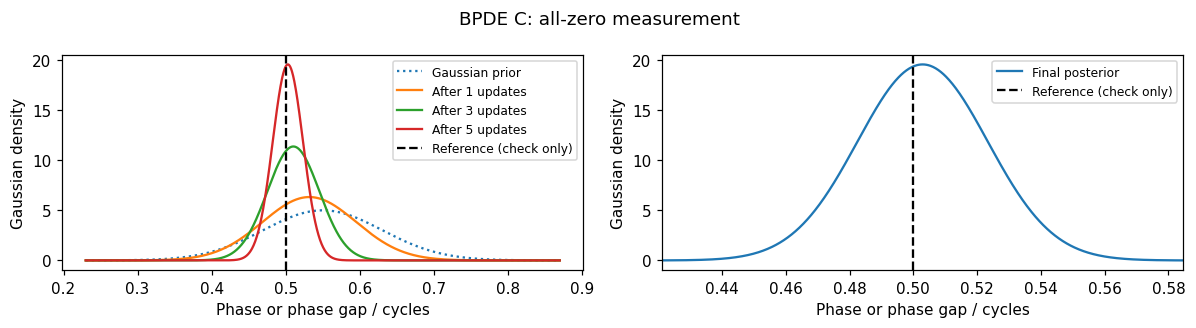

In [12]:
c_rows = gaussian_updates(
    lambda L,b: measurement_probabilities(return_circuit(eta=0,L=L,beta=b,kind='C'))[1],
    initial_mu=.55, initial_sd=.08, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=83)
plot_updates(c_rows, GAP, 'BPDE C: all-zero measurement')
print_data(c_rows)
for L in [1,2,5]:
    beta=-TAU*L*.43
    np.testing.assert_allclose(ancilla_zero(bpde_circuit(L=L,beta=beta)),
        measurement_probabilities(return_circuit(L=L,beta=beta))[1],atol=ATOL)

### 確認と解答：全0測定と近似準備

1. Cの`[1]`を`[0]`に変えればよいか。  
   **解答：** いけません。このCの例では補助0の確率は常に1で、ギャップの山がありません。
   一定値にGaussianを当てはめてもギャップの推定になりません。
2. `eta=.25`でも全0測定なら厳密なギャップだけが残るか。  
   **解答：** いいえ。第5節の図のとおり、複数の位相が混ざり曲線が変形します。
   フィット中心が偏る可能性もあり、残差と準備の精度を確認します。全0測定は状態を浄化する操作ではありません。
3. $\beta=0,L=1$でB・Cの測定確率はどう違うか。  
   **解答：** Bは補助0も全0も0、Cは補助0が1で全0は0です。測るビットを明示する必要があります。

## 6．次の分子計算へ

演習2以降の$U=e^{-iH\Delta t}$では$\phi=-E\Delta t/(2\pi)\pmod1$です。
固有値の候補$\epsilon=-E_{\rm trial}\Delta t/(2\pi)$を代入すると、
本冊の補正角$\beta=-2\pi L\epsilon$は$\beta=E_{\rm trial}t$（$t=L\Delta t$）になります。
ギャップでも$\beta=\Delta E_{\rm trial}t$となります。符号が変わる理由は時間発展の指数の符号です。

| 本冊 | 次冊以降で使う考え方 |
|---|---|
| QPE | ビット列をエネルギーに換算する |
| BPE | 候補を走査して単一固有値の山を探す |
| BPDE B | 系の制御時間発展なしに差を測る |
| BPDE C | 全0頻度で差の山を探す。近似準備では偏りにも注意する |
| Gaussian更新 | 05と同じ「事前→計画→測定→フィット→事後→次の事前」 |

本冊と05では物理量・時間の単位と測定計画の係数が異なります。
また、既存の番号付き02・03の二項尤度の例は別の更新法です。02は本冊と同じGaussian更新です。Gaussian近似との違いは下の補足で確認できます。

[参考論文](https://doi.org/10.1073/pnas.2425026122)：Fig. 1B/1Cの読出しを参照。
本冊は2×2行列を用いた説明用実装です。

## 補足（本編の実行には不要）：二項尤度による更新との違い

元の01は、固定した$(L,\beta)$ごとのcountsを使ってグリッド分布を更新していました。
その方法は
$$p_{\rm new}(\phi)\propto p_{\rm old}(\phi)
 P_0(\phi)^{n_0}[1-P_0(\phi)]^{R-n_0}$$
という二項尤度の更新です。$\beta=0,-\pi/2$の二つを測るのは余弦・正弦の両成分を見るためで、測定結果から選んでいたのではありません。
本編はこの設定列を使わず、候補$\epsilon$ごとに$\beta$を変え、信号の一つの山をGaussianで近似しています。
厳密な二項更新とGaussian信号フィットによる更新を同一視しないでください。